# ΔMFI-Radarplots

Infos bei Mitbenutzung:
Eine CSV pro Marker und ein Ordner pro Kohorte. CSV: erste Spalte Dosis, weitere Spalten -TNF/+TNF. Gleiche Marker müssen in allen Ordnern gleich heißen. Dezimalkommas werden eingelesen.

Alle passenden Zeilen werden gleich gewichtet. Technische Replikate gegebenenfalls vorher pro biologischer Probe mitteln. Bei sehr kleinen positiven Kontrollwerten können Quotienten extrem groß werden; das Skript bewertet die biologische Eignung der Normierung nicht. Nichtpositive Kontrollen und negative Gruppenmittel werden für diesen Radarplot abgelehnt. Mindestens drei Marker erforderlich.


In [19]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def _dose_key(value):
    """Dosisangaben wie '0Gy', '0 Gy', '0.1Gy' oder '0,1Gy' vereinheitlichen."""
    text = str(value).strip().lower().replace(",", ".")
    text = re.sub(r"\s*gy\s*$", "", text)
    return float(text)


def collect_marker_means(
    folder,
    tnf="-TNF",
    dose="0Gy",
    pattern="*.csv",
    sep=None,
):
    """
    Liest eine CSV pro Marker aus einem Ordner ein.

    Erwartetes CSV-Format:
        Erste Spalte: Dosis
        Weitere Spalten: beispielsweise '-TNF' und '+TNF'

    Filtert auf die ausgewählte Dosis und TNF-Spalte und berechnet
    pro Datei den arithmetischen Mittelwert.

    Parameter
    ---------
    folder : str oder Path
        Ordner mit den Marker-CSVs.
    tnf : str
        Name der auszuwertenden Messwertspalte.
    dose : str oder float
        Gewünschte Dosis, beispielsweise '0Gy' oder '0.1Gy'.
    pattern : str
        Dateimuster, beispielsweise '*.csv' oder '*_Haut.csv'.
    sep : str oder None
        None erkennt das Trennzeichen automatisch.
        Alternativ ',' oder ';' angeben.

    Rückgabe
    --------
    list[dict]
        Ein Dictionary pro Marker mit:
        marker, mean, n, sd und file.

    Hinweise
    --------
    Alle ausgewählten Zeilen werden gleich gewichtet.
    Negative Messwerte bleiben bei der Mittelwertbildung erhalten.
    Leere Messwerte werden übersprungen; ungültige Werte führen
    zu einer Fehlermeldung.
    """
    folder = Path(folder).expanduser()

    if not folder.is_dir():
        raise NotADirectoryError(f"Ordner nicht gefunden: {folder}")

    files = sorted(folder.glob(pattern))

    if not files:
        raise FileNotFoundError(
            f"Keine CSV-Dateien in '{folder}' für Muster '{pattern}'."
        )

    target_dose = _dose_key(dose)
    results = []
    missing_tokens = {"", "na", "nan", "n/a", "null"}

    for path in files:
        df = pd.read_csv(
            path,
            sep=sep,
            engine="python",
            dtype=str,
            encoding="utf-8-sig",
            keep_default_na=False,
        )

        df.columns = df.columns.str.strip()

        if df.shape[1] < 2:
            raise ValueError(
                f"{path.name}: Mindestens eine Dosisspalte und "
                "eine Messwertspalte erforderlich."
            )

        if df.columns.duplicated().any():
            raise ValueError(
                f"{path.name}: Doppelte Spaltennamen vorhanden."
            )

        if tnf not in df.columns:
            raise ValueError(
                f"{path.name}: Spalte '{tnf}' fehlt. "
                f"Vorhanden: {list(df.columns)}"
            )

        try:
            doses = df.iloc[:, 0].map(_dose_key)
        except (ValueError, TypeError) as exc:
            raise ValueError(
                f"{path.name}: Die erste Spalte enthält "
                "ungültige Dosiswerte."
            ) from exc

        mask = np.isclose(
            doses,
            target_dose,
            rtol=0,
            atol=1e-9,
        )

        raw = df.loc[mask, tnf]

        if raw.empty:
            raise ValueError(
                f"{path.name}: Keine Zeilen für Dosis '{dose}'."
            )

        text = raw.str.strip()
        is_missing = text.str.lower().isin(missing_tokens)

        values = pd.to_numeric(
            text.str.replace(",", ".", regex=False),
            errors="coerce",
        )

        invalid = (
            ~is_missing
            & (values.isna() | ~np.isfinite(values))
        )

        if invalid.any():
            raise ValueError(
                f"{path.name}: Ungültige Messwerte: "
                f"{raw[invalid].tolist()}"
            )

        values = values[~is_missing]

        if values.empty:
            raise ValueError(
                f"{path.name}: Keine gültigen Messwerte "
                f"für {tnf}, {dose}."
            )

        results.append(
            {
                "marker": path.stem,
                "mean": float(values.mean()),
                "n": int(values.size),
                "sd": (
                    float(values.std(ddof=1))
                    if values.size > 1
                    else float("nan")
                ),
                "file": str(path),
            }
        )

    return results


def plot_normalized_radar(
    control,
    groups=None,
    control_label="Kontrolle",
    markers=None,
    title="Markerprofil",
    rmax=None,
    colors=None,
    save=None,
):
    """
    Erstellt einen Radar-Plot aus Marker-Ergebnislisten.

    Normalisierung pro Marker:
        Gruppenmittelwert / Kontrollmittelwert

    Negative Vergleichsmittelwerte:
        Werden mit einer Warnung auf 0 gesetzt, ausschließlich
        für die normalisierte Tabelle und den Plot.
        Die ursprünglichen Ergebnislisten bleiben unverändert.

    Kontrollmittelwerte:
        Müssen strikt größer als 0 sein.
        Andernfalls wird eine Fehlermeldung ausgegeben.

    Parameter
    ---------
    control : list[dict]
        Kontrollliste aus collect_marker_means().
    groups : dict[str, list[dict]] oder None
        Weitere Gruppen, beispielsweise:
        {"Female 6 weeks": female_6w, "Male 1 year": male_1y}
    control_label : str
        Name der Kontrollgruppe in Tabelle und Legende.
    markers : list[str] oder None
        Optionale Markerauswahl und Reihenfolge.
        Ohne Auswahl müssen alle Gruppen denselben Markersatz haben.
    title : str
        Titel des Plots.
    rmax : float oder None
        Obergrenze der radialen Achse.
        None bestimmt sie automatisch.
    colors : list[str] oder None
        Farben; erste Farbe für die Kontrolle.
    save : str oder Path oder None
        Optionaler Speicherpfad, beispielsweise 'figures/radar.svg'.

    Rückgabe
    --------
    fig, ax, normalized
        Matplotlib-Figure, Achse und Tabelle der geplotteten
        normalisierten Mittelwerte.
    """
    groups = {} if groups is None else groups

    if control_label in groups:
        raise ValueError(
            "'control_label' darf nicht zusätzlich "
            "als Gruppenname vorkommen."
        )

    def as_series(records, name):
        table = pd.DataFrame(records)

        if not {"marker", "mean"}.issubset(table.columns):
            raise ValueError(
                f"{name}: Die Ergebnisliste benötigt "
                "die Felder 'marker' und 'mean'."
            )

        if table["marker"].duplicated().any():
            duplicates = table.loc[
                table["marker"].duplicated(keep=False),
                "marker",
            ].tolist()

            raise ValueError(
                f"{name}: Doppelte Markernamen: {duplicates}"
            )

        series = table.set_index("marker")["mean"].astype(float)

        if not np.isfinite(series.to_numpy()).all():
            raise ValueError(
                f"{name}: Nicht-endliche Mittelwerte vorhanden."
            )

        return series

    # Kontrolle und Markerauswahl vorbereiten.
    reference = as_series(control, control_label)

    selected = (
        list(reference.index)
        if markers is None
        else list(markers)
    )

    if len(selected) < 3 or len(set(selected)) != len(selected):
        raise ValueError(
            "Mindestens drei unterschiedliche Marker auswählen."
        )

    missing = set(selected) - set(reference.index)

    if missing:
        raise ValueError(
            f"Kontrolle: Marker fehlen: {sorted(missing)}"
        )

    reference = reference.loc[selected]

    # Nichtpositive Kontrollmittelwerte niemals auf 0 setzen.
    invalid_reference = reference[reference <= 0]

    if not invalid_reference.empty:
        details = "; ".join(
            f"Marker '{marker}': {value:.6g}"
            for marker, value in invalid_reference.items()
        )

        raise ValueError(
            f"Kontrollgruppe '{control_label}' enthält "
            f"Mittelwerte ≤ 0: {details}. "
            "Eine Fold-Change-Normalisierung auf diese Werte "
            "ist nicht möglich. Betroffene Marker über "
            "'markers=' ausschließen oder eine andere "
            "Kontrollgruppe wählen."
        )

    # Die Kontrolle entspricht für jeden Marker 1×.
    normalized = pd.DataFrame(
        {control_label: np.ones(len(selected))},
        index=selected,
    )

    for name, records in groups.items():
        series = as_series(records, name)

        if markers is None and set(series.index) != set(reference.index):
            missing = sorted(set(reference.index) - set(series.index))
            extra = sorted(set(series.index) - set(reference.index))

            raise ValueError(
                f"{name}: Markersatz weicht von der Kontrolle ab. "
                f"Fehlend: {missing}; zusätzlich: {extra}. "
                "Dateinamen angleichen oder 'markers' explizit wählen."
            )

        missing = set(selected) - set(series.index)

        if missing:
            raise ValueError(
                f"{name}: Marker fehlen: {sorted(missing)}"
            )

        # Kopie: Originaldaten bleiben unverändert.
        values = series.loc[selected].copy()

        for marker, value in values[values < 0].items():
            warnings.warn(
                f"Gruppe '{name}', Marker '{marker}': "
                f"negativer ΔMFI-Mittelwert ({value:.6g}). "
                "Für den Plot auf 0 gesetzt; "
                "Originaldaten unverändert.",
                UserWarning,
                stacklevel=2,
            )

        values = values.clip(lower=0)
        normalized[name] = values / reference

    normalized.index.name = "marker"

    if not np.isfinite(normalized.to_numpy()).all():
        raise ValueError(
            "Die Normalisierung hat nicht-endliche Werte erzeugt. "
            "Kontrollmittelwerte auf extrem kleine Werte prüfen."
        )

    # Geschlossene Polygonkoordinaten.
    angles = np.linspace(
        0,
        2 * np.pi,
        len(selected),
        endpoint=False,
    )
    closed_angles = np.r_[angles, angles[0]]

    maximum = float(normalized.to_numpy().max())

    if rmax is None:
        rmax = max(
            1.5,
            np.ceil(maximum * 1.1 * 2) / 2,
        )

    if not np.isfinite(rmax) or rmax <= maximum:
        raise ValueError(
            f"'rmax' muss endlich und größer als der höchste "
            f"normierte Wert ({maximum:.3g}) sein."
        )

    palette = (
        list(colors)
        if colors is not None
        else [
            "#2685c7",
            "#f39a24",
            "#2ca02c",
            "#bd4545",
            "#9467bd",
            "#17becf",
        ]
    )

    if not palette:
        raise ValueError("'colors' darf nicht leer sein.")

    with plt.rc_context({"font.family": "DejaVu Sans"}):
        fig, ax = plt.subplots(
            figsize=(8, 6),
            subplot_kw={"projection": "polar"},
        )

        ax.set_theta_offset(np.pi / 2)
        ax.set_theta_direction(-1)
        ax.set_ylim(0, rmax)

        ax.grid(False)
        ax.spines["polar"].set_visible(False)

        ticks = np.unique(
            np.r_[
                np.linspace(0, rmax, 5)[1:],
                1.0,
            ]
        )

        # Polygonales Gitternetz.
        for radius in ticks:
            ax.plot(
                closed_angles,
                np.full(closed_angles.size, radius),
                color="#c4c4c4",
                linewidth=0.8,
                zorder=0,
            )

        for angle in angles:
            ax.plot(
                [angle, angle],
                [0, rmax],
                color="#c4c4c4",
                linewidth=0.8,
                zorder=0,
            )

        ax.set_xticks(angles)
        ax.set_xticklabels(selected, fontsize=10)
        ax.tick_params(axis="x", pad=12)

        ax.set_yticks(ticks)
        ax.set_yticklabels(
            [f"{value:g}×" for value in ticks],
            fontsize=8,
            color="#5555bb",
        )
        ax.set_rlabel_position(0)

        for i, name in enumerate(normalized.columns):
            values = normalized[name].to_numpy()
            closed_values = np.r_[values, values[0]]
            color = palette[i % len(palette)]

            ax.fill(
                closed_angles,
                closed_values,
                color=color,
                alpha=0.14,
                zorder=2,
            )

            ax.plot(
                closed_angles,
                closed_values,
                color=color,
                linewidth=1.6,
                marker="o",
                markersize=4,
                linestyle="--" if i == 0 else "-",
                label=name,
                zorder=3,
            )

        ax.set_title(title, fontsize=15, pad=30)

        ax.legend(
            loc="upper left",
            bbox_to_anchor=(1.15, 1.05),
            frameon=False,
        )

        fig.subplots_adjust(
            left=0.12,
            right=0.70,
            top=0.80,
            bottom=0.12,
        )

        if save is not None:
            path = Path(save)
            path.parent.mkdir(parents=True, exist_ok=True)

            fig.savefig(
                path,
                dpi=300,
                bbox_inches="tight",
            )

    return fig, ax, normalized

## Ordner einlesen
Pfade anpassen. Die Beispiele werden nicht automatisch ausgeführt.

In [78]:
#male_6w = collect_marker_means("/home/tom/Desktop/Radar/ohneCD95//m6w/Haut/", tnf="+TNF", dose="0Gy")
#female_6w = collect_marker_means("/home/tom/Desktop/Radar/ohneCD95/f6w/Haut/", tnf="-TNF", dose="0Gy")
#male_14w = collect_marker_means("/home/tom/Desktop/Radar/ohneCD95/m14w/Haut", tnf="-TNF", dose="0Gy")
#female_14w = collect_marker_means("/home/tom/Desktop/Radar/ohneCD95/f14w/Haut", tnf="-TNF", dose="0Gy")
male_1y = collect_marker_means("/home/tom/Desktop/Radar/ohneCD95/m1y/Haut", tnf="+TNF", dose="0Gy")
female_1y = collect_marker_means("/home/tom/Desktop/Radar/ohneCD95/f1y/Haut", tnf="+TNF", dose="0Gy")

# Ergebnisliste und tabellarische Ansicht:
#display(female_6w)
display(pd.DataFrame(female_6w))

,marker,mean,n,sd,file
0,CD140a_Haut,115618.070000,3,37130.357376,/home/tom/Desktop/Radar/ohneCD95/f6w/Haut/CD14...
1,CD39_Haut,16139.053333,3,12611.723392,/home/tom/Desktop/Radar/ohneCD95/f6w/Haut/CD39...
2,CD44_Haut,198100.556667,3,127558.064771,/home/tom/Desktop/Radar/ohneCD95/f6w/Haut/CD44...
3,CD49b_Haut,4604.333333,3,2738.534159,/home/tom/Desktop/Radar/ohneCD95/f6w/Haut/CD49...
4,CD87_Haut,26852.346667,3,9313.181814,/home/tom/Desktop/Radar/ohneCD95/f6w/Haut/CD87...
5,FAP_Haut,755.780000,3,358.221019,/home/tom/Desktop/Radar/ohneCD95/f6w/Haut/FAP_...
6,Ly6AE_Haut,438814.933333,3,293813.757762,/home/tom/Desktop/Radar/ohneCD95/f6w/Haut/Ly6A...
7,Ly6C_Haut,14531.490000,3,10013.565960,/home/tom/Desktop/Radar/ohneCD95/f6w/Haut/Ly6C...
8,alphaSMA_Haut,652293.626667,3,147049.976505,/home/tom/Desktop/Radar/ohneCD95/f6w/Haut/alph...


## Auf Kontrolle normieren und darstellen
1× entspricht dem Kontrollmittel je Marker, 1.5× entspricht 50 % darüber. Es werden Verhältnisse von Gruppenmitteln dargestellt, keine gepaarten Einzelquotienten.

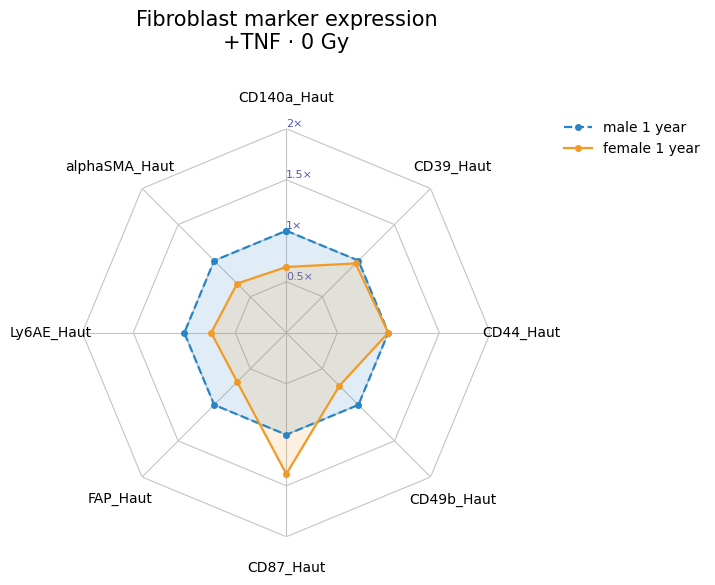

In [79]:
fig, ax, normalized = plot_normalized_radar(
    control=male_1y,
    control_label="male 1 year",
    groups={"female 1 year": female_1y},
    title="Fibroblast marker expression\n+TNF · 0 Gy",
    save="figures/radar_0Gy_minusTNF.svg",
)
plt.savefig("/home/tom/Desktop/Radar/female_male1y_Haut_0Gy_+TNF.png")
plt.show()


# Optional: Tabellen exportieren
# pd.DataFrame(male_6w).to_csv("male_6w_means.csv", index=False)
# normalized.to_csv("normalized_means.csv")